# import libraries and modules

In [3]:
import os  
import numpy as np 
import random 
from PIL import Image, ImageEnhance 

#keras library tools
from tensorflow.keras.preprocessing.image import load_img  
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Input, Flatten, Dropout, Dense 
from tensorflow.keras.optimizers import Adam  
from tensorflow.keras.applications import VGG16 

from sklearn.utils import shuffle  

# loading dataset

In [4]:
dataset_path = "brain_tumor_dataset"

print(os.listdir(dataset_path))

['Testing', 'Training']


In [5]:
# Directories for training and testing data
train_dir = 'brain_tumor_dataset/Training/'
test_dir = 'brain_tumor_dataset/Testing/'

# Load and shuffle the train data
train_paths = []   #to store train images
train_labels = []      # to read labels
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)
    

train_paths, train_labels = shuffle(train_paths, train_labels)

# Load and shuffle the test data
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)


# data visualization

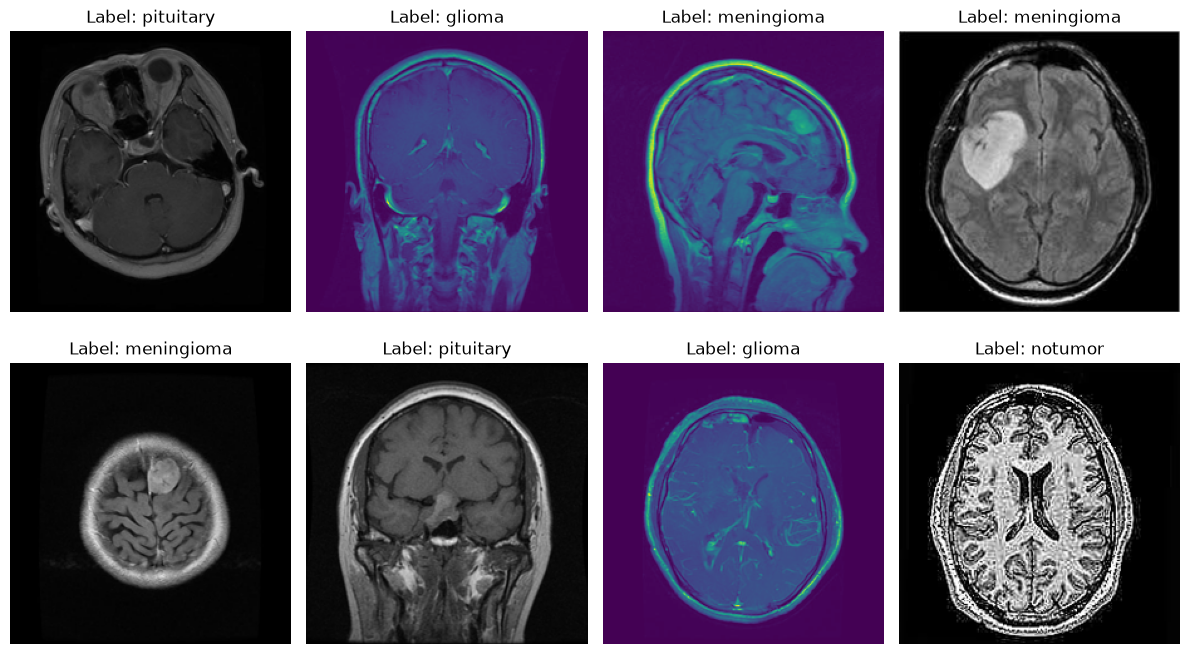

In [6]:
import matplotlib.pyplot as plt


# Select random indices for 10 images
random_indices = random.sample(range(len(train_paths)), 8)

# Create a figure to display images in 2 rows
fig, axes = plt.subplots(2, 4, figsize=(12, 7))
axes = axes.ravel()

for i, idx in enumerate(random_indices):        #make index for every index
    # Load image
    img_path = train_paths[idx]
    img = Image.open(img_path)
    img = img.resize((224, 224))  # Resize to consistent size

    # Display image
    axes[i].imshow(img)
    axes[i].axis('off')  # Hide axis
    # Display class label in the second row
    axes[i].set_title(f"Label: {train_labels[idx]}", fontsize=12)

plt.tight_layout()
plt.show()

# image preprocessing

In [7]:
#preprocess and return image in array 
def augment_image(image):
    image = Image.fromarray(np.uint8(image))   #converting image into unsigned integer
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))  # Random brightness
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))  # Random contrast
    image = np.array(image) / 255.0  # Normalize pixel values to [0, 1]
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image = augment_image(image) # calling above function to get preprocessed image
        images.append(image)
    return np.array(images)

# Encoding labels (convert label names to integers)
def encode_label(labels):
    unique_labels = os.listdir(train_dir)  # Ensure unique labels are determined
    encoded = [unique_labels.index(label) for label in labels] #runs 4 times
    return np.array(encoded)  #return [0,1,2,3]

# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch

### WE ARE USING VGG16 FOR TRANSFER LEARNING.
The model is built on top of VGG16, which is a pre-trained convolutional neural network (CNN) for image classification.

First, the VGG16 model is loaded with input_shape=(IMAGE_SIZE,IMAGE_SIZE,3), include_top=False, weights='imagenet'. The input shape is set to match the size of the images in the dataset, which is 128x128 pixels. The include_top parameter is set to False, which means that the final fully-connected layers of VGG16 that perform the classification will not be included. The weights parameter is set to 'imagenet' which means that the model will be pre-trained with a dataset of 1.4 million images called imagenet

Next, the for layer in base_model.layers: loop is used to set all layers of the base_model (VGG16) to non-trainable, so that the weights of these layers will not be updated during training.

Then, the last three layers of the VGG16 model are set to trainable by using base_model.layers[-2].trainable = True,base_model.layers[-3].trainable = True and base_model.layers[-4].trainable = True

After that, a Sequential model is created and the VGG16 model is added to it with model.add(base_model).

Next, a Flatten layer is added to the model with model.add(Flatten()) which reshapes the output of the VGG16 model from a 3D tensor to a 1D tensor, so that it can be processed by the next layers of the model.

Then, a Dropout layer is added with model.add(Dropout(0.3)) which is used to prevent overfitting by randomly setting a fraction of input units to 0 at each update during training time.

After that, a dense layer is added with 128 neurons and relu activation function is added with model.add(Dense(128, activation='relu')).

Next, another Dropout layer is added with model.add(Dropout(0.2))

Finally, the output dense layer is added with number of neurons equal to the number of unique labels and 'softmax' activation function is added with model.add(Dense(len(unique_labels), activation='softmax')). The 'softmax' activation function is used to give a probability distribution over the possible classes.

In [8]:
# Model architecture
IMAGE_SIZE = 128  # Image size (adjust based on your requirements , 3 represents channel( RGB)) 
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet') 

# Freeze all layers of the VGG16 base model
for layer in base_model.layers:
    layer.trainable = False

# Set the last few layers of the VGG16 base model to be trainable
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

# Build the final model
model = Sequential()   #building model layer by layer
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))  # Input layer :first layer 
model.add(base_model)  # Add VGG16 base model 
model.add(Flatten())  # Flatten the output of the base model
model.add(Dropout(0.3))  # Dropout layer for regularization # it removes almost 30% neuron to protect it from overfitting.
model.add(Dense(128, activation='relu'))  # Dense layer with ReLU activation
model.add(Dropout(0.2))  # Dropout layer for regularization dropping 20% data
model.add(Dense(len(os.listdir(train_dir)), activation='softmax')) # Output layer with softmax activation ,informing model about multiclass classification


# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),  #during backpropogation weights are update according to learning rate 
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

# Parameters
batch_size = 20
steps = int(len(train_paths) / batch_size)  # Steps per epoch
epochs = 10 # no. of times to train model

# Train the model
history = model.fit(datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
                    epochs=epochs, steps_per_epoch=steps)

D:\code\vs\project\brain_tumor_detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 173s 609ms/step - loss: 0.4733 - sparse_categorical_accuracy: 0.8173
Epoch 2/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 167s 595ms/step - loss: 0.2446 - sparse_categorical_accuracy: 0.9118
Epoch 3/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 162s 576ms/step - loss: 0.1600 - sparse_categorical_accuracy: 0.9383
Epoch 4/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 162s 575ms/step - loss: 0.1172 - sparse_categorical_accuracy: 0.9583
Epoch 5/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 159s 566ms/step - loss: 0.0768 - sparse_categorical_accuracy: 0.9708
Epoch 6/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 157s 560ms/step - loss: 0.0727 - sparse_categorical_accuracy: 0.9713
Epoch 7/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 159s 566ms/step - loss: 0.0496 - sparse_categorical_accuracy: 0.9824
Epoch 8/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 162s 575ms/step - loss: 0.0492 - sparse_categorical_accuracy: 0.9824
Epoch 9/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 161s 574ms/step - loss: 0.0435 - sparse_categorical_accuracy: 0.9845
Epoch 10/10
281/281

# Train and value plots

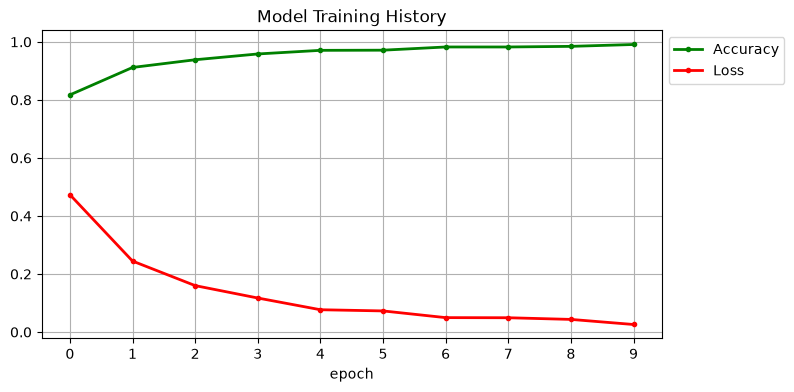

In [9]:
#plot graph showing model performance
plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'], '.g-', linewidth=2)
plt.plot(history.history['loss'], '.r-', linewidth=2)
plt.title('Model Training History')
plt.xlabel('epoch')
plt.xticks([x for x in range(epochs)])
plt.legend(['Accuracy', 'Loss'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

# model classification report

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns
from sklearn.preprocessing import label_binarize
from tensorflow.keras.models import load_model
import numpy as np


# 1. Prediction on test data
test_images = open_images(test_paths)  # Load and augment test images
test_labels_encoded = encode_label(test_labels)  # Encode the test labels

# Predict using the trained model
test_predictions = model.predict(test_images)

# 2. Classification Report
print("Classification Report:")
print(classification_report(test_labels_encoded, np.argmax(test_predictions, axis=1)))

50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 724ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.64      0.77       400
           1       0.85      0.91      0.88       400
           2       0.78      1.00      0.87       400
           3       0.97      0.96      0.97       400

    accuracy                           0.88      1600
   macro avg       0.89      0.88      0.87      1600
weighted avg       0.89      0.88      0.87      1600



# model confusion plot

Confusion Matrix:
[[254  61  77   8]
 [  5 363  29   3]
 [  0   0 400   0]
 [  1   4  10 385]]


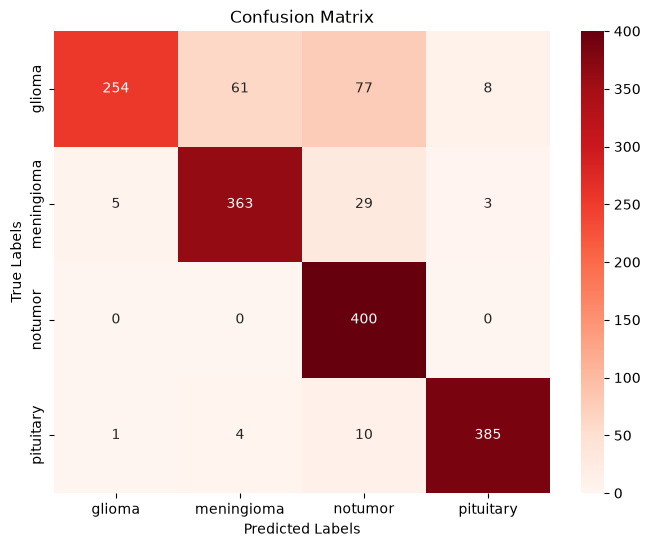

In [17]:
# 3. Confusion Matrix
conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(test_predictions, axis=1))
print("Confusion Matrix:")
print(conf_matrix)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Reds", xticklabels=os.listdir(train_dir), yticklabels=os.listdir(train_dir))
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# roc curve

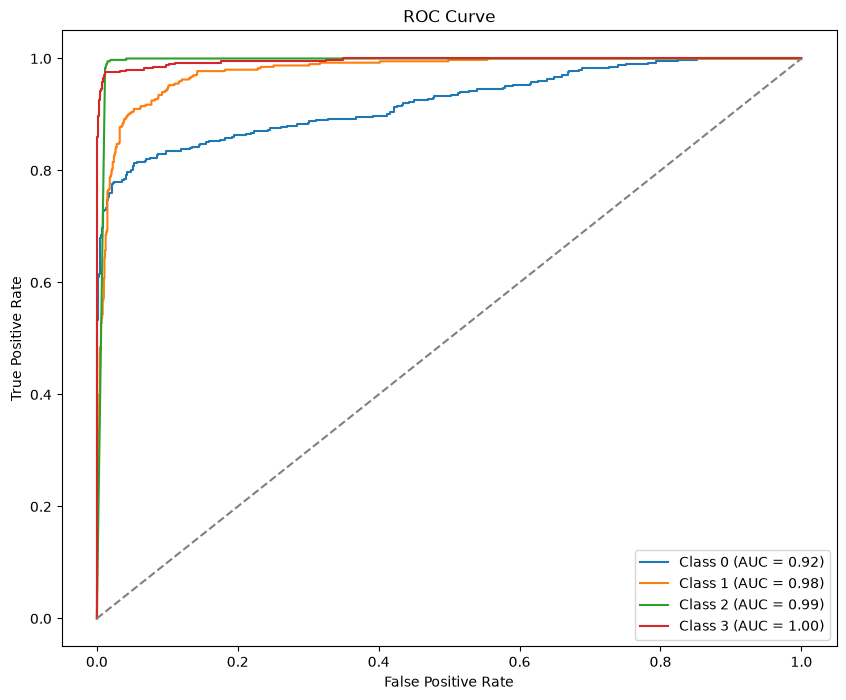

In [18]:
# 4. ROC Curve and AUC
# Binarize the test labels and predictions for multi-class ROC
test_labels_bin = label_binarize(test_labels_encoded, classes=np.arange(len(os.listdir(train_dir))))
test_predictions_bin = test_predictions  # The predicted probabilities for each class

# Compute ROC curve and ROC AUC for each class
fpr, tpr, roc_auc = {}, {}, {}
for i in range(len(os.listdir(train_dir))):
    fpr[i], tpr[i], _ = roc_curve(test_labels_bin[:, i], test_predictions_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curve
plt.figure(figsize=(10, 8))
for i in range(len(os.listdir(train_dir))):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # Diagonal line
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

# save & load model

In [20]:
# Save the entire model
model.save('model.h5')

In [21]:
from tensorflow.keras.models import load_model
# Load the trained model
model = load_model('model.h5')

# MRI Tumor Detection sytem

In [22]:
from keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Class labels
class_labels = ['pituitary', 'glioma', 'notumor', 'meningioma']

def detect_and_display(img_path, model, image_size=128):
    """
    Function to detect tumor and display results.
    If no tumor is detected, it displays "No Tumor".
    Otherwise, it shows the predicted tumor class and confidence.
    """
    try:
        # Load and preprocess the image
        img = load_img(img_path, target_size=(image_size, image_size))
        img_array = img_to_array(img) / 255.0  # Normalize pixel values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Make a prediction
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions, axis=1)[0]
        confidence_score = np.max(predictions, axis=1)[0]

        # Determine the class
        if class_labels[predicted_class_index] == 'notumor':
            result = "No Tumor"
        else:
            result = f"Tumor: {class_labels[predicted_class_index]}"

        # Display the image with the prediction
        plt.imshow(load_img(img_path))
        plt.axis('off')
        plt.title(f"{result} (Confidence: {confidence_score * 100:.2f}%)")
        plt.show()

    except Exception as e:
        print("Error processing the image:", str(e))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


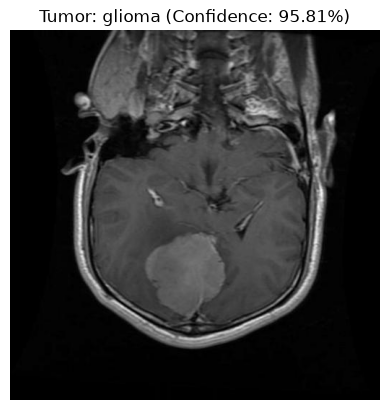

In [56]:
# Example usage
image_path = 'brain_tumor_dataset\Testing\glioma\Te-aug-me_69.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step


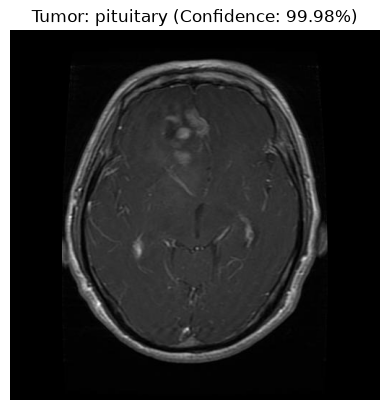

In [66]:
# Example usage
image_path = 'brain_tumor_dataset/Testing/pituitary/Te-gl_5.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step


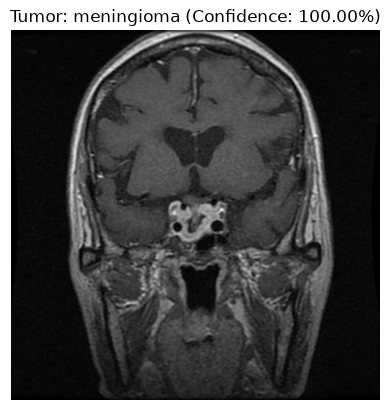

In [64]:
# Example usage
image_path = 'brain_tumor_dataset/Testing/meningioma/Te-pi_371.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


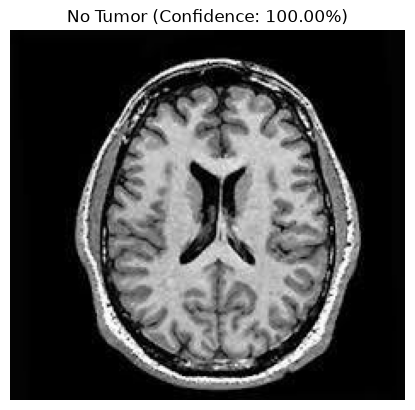

In [63]:
# Example usage
image_path = 'brain_tumor_dataset/Testing/notumor/Te-no_2.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)